In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer

In [11]:
df = pd.read_csv('../data/inverted.txt')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [13]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [14]:
target = "converted"
categorical = [c for c in df.columns if df[c].dtype == "object" or str(df[c].dtype) == "str"]
numerical = [c for c in df.columns if c not in categorical and c != target]


print("Categorical columns:", categorical)
print("Numerical columns:", numerical)

Categorical columns: ['lead_source', 'industry', 'employment_status', 'location']
Numerical columns: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


In [15]:
for c in categorical:
    df[c] = df[c].fillna("NA")
for c in numerical:
    df[c] = df[c].fillna(0.0)

In [16]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

y_train = df_train[target].values
y_val = df_val[target].values
print("Split sizes:", len(df_train), len(df_val), len(df_test), "\n")

Split sizes: 3000 1000 1000 



In [18]:
features = categorical + numerical

In [24]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(df_tr[features].to_dict(orient="records"))
    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model


def predict(dv, model, df_x):
    X = dv.transform(df_x[features].to_dict(orient="records"))
    return model.predict_proba(X)[:, 1]

In [25]:
vars = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]
r_a_score = {}
for c in vars:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])
    r_a_score[c] = auc
    print(f"  {c:28s} {auc:.4f}")
print("  -> highest:", max(r_a_score, key=r_a_score .get), "\n")

  lead_score                   0.7882
  number_of_courses_viewed     0.7230
  interaction_count            0.7649
  annual_income                0.6082
  -> highest: lead_score 



In [26]:
dv, model = train(df_train, y_train, C=1.0)
y_pred = predict(dv, model, df_val)
print(f"validation AUC = {roc_auc_score(y_val, y_pred):.3f}\n")

validation AUC = 0.732



In [27]:
rows = []
for t in np.arange(0.0, 1.01, 0.01):
    pred_pos = y_pred >= t
    tp = (pred_pos & (y_val == 1)).sum()
    fp = (pred_pos & (y_val == 0)).sum()
    fn = (~pred_pos & (y_val == 1)).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((round(t, 2), p, r, f1))

scores = pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])
scores

,threshold,precision,recall,f1
0,0.00,0.586,1.000000,0.738966
1,0.01,0.586,1.000000,0.738966
2,0.02,0.586,1.000000,0.738966
3,0.03,0.586,1.000000,0.738966
4,0.04,0.586,1.000000,0.738966
...,...,...,...,...
96,0.96,1.000,0.001706,0.003407
97,0.97,0.000,0.000000,0.000000
98,0.98,0.000,0.000000,0.000000
99,0.99,0.000,0.000000,0.000000


In [31]:
nonzero = scores[(scores.precision > 0) | (scores.recall > 0)].copy()

nonzero["diff"] = (nonzero.precision - nonzero.recall).abs()
best_diff = nonzero.loc[nonzero["diff"].idxmin()]

print(f"precision/recall intersect at threshold = {best_diff.threshold:.2f}")

precision/recall intersect at threshold = 0.63


In [32]:
best = scores.loc[scores.f1.idxmax()]
print(f"max F1 = {best.f1:.4f} at threshold = {best.threshold:.2f}\n")

max F1 = 0.7576 at threshold = 0.41



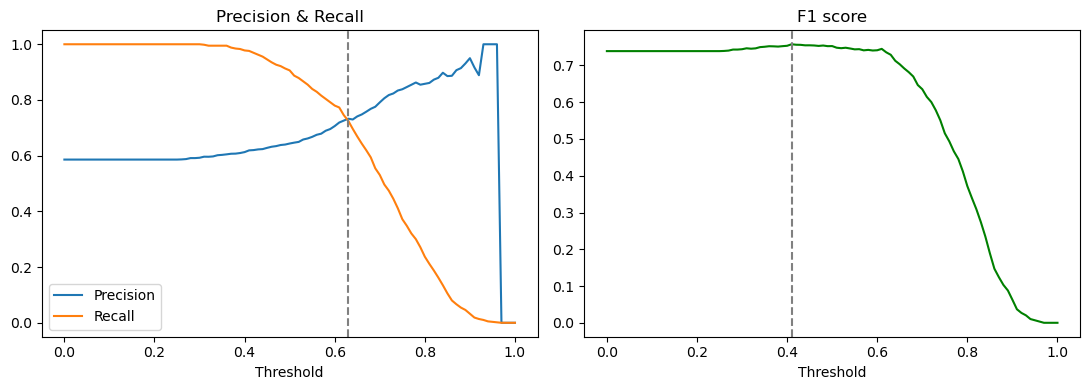

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(scores.threshold, scores.precision, label="Precision")
axes[0].plot(scores.threshold, scores.recall, label="Recall")
axes[0].axvline(best_diff.threshold, color="gray", linestyle="--")
axes[0].set_xlabel("Threshold")
axes[0].set_title("Precision & Recall")
axes[0].legend()

axes[1].plot(scores.threshold, scores.f1, color="green")
axes[1].axvline(best.threshold, color="gray", linestyle="--")
axes[1].set_xlabel("Threshold")
axes[1].set_title("F1 score")

plt.tight_layout()
plt.show()

In [35]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)


def cross_validate(C):
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv_, m_ = train(d_tr, d_tr[target].values, C=C)
        preds = predict(dv_, m_, d_va)
        aucs.append(roc_auc_score(d_va[target].values, preds))
    return np.array(aucs)


scores_c1 = cross_validate(1.0)
print("fold AUCs:", scores_c1.round(4))
print(f"    std = {scores_c1.std():.3f}\n")



fold AUCs: [0.7306 0.7296 0.7363 0.7412 0.7209]
    std = 0.007



In [36]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C)
    results.append((C, round(s.mean(), 3), round(s.std(), 3)))
    print(f"  C={C:<9} mean={s.mean():.3f}  std={s.std():.3f}")

# Best: highest mean, then lowest std, then smallest C
best_C = sorted(results, key=lambda r: (-r[1], r[2], r[0]))[0][0]
print("  -> best C:", best_C)

  C=1e-06     mean=0.617  std=0.019
  C=0.001     mean=0.749  std=0.010
  C=1         mean=0.732  std=0.007
  -> best C: 0.001
